In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
dataset=pd.read_csv("/content/lahore_house_listings_zameen.csv")
dataset.shape

(18249, 23)

In [5]:
dataset.head()

,Title,Location,Type,Price,Area,Bedrooms,Bathrooms,Purpose,Date Posted,Built Year,...,Furnished,Gym,Study Room,Drawing Room,Dining Room,Lawn/Garden,Swimming Pool,Electricity Backup,Lounge/Sitting Room,Link
0,ACTUALLY 25 MARLA DOUBLE UNIT LUXURIOUS & GRAC...,"DHA Phase 6 - Block F, DHA Phase 6, DHA Defenc...",House,8.15 Crore,1 Kanal,6,7,For Sale,2025-07-27,2024.0,...,True,True,True,True,True,True,True,True,True,https://www.zameen.com/Property/dha_phase_6_dh...
1,3 Years Installment Plan Luxury Brand New Hous...,"Park View City, Lahore, Punjab",House,1.5 Crore,5 Marla,4,5,For Sale,2025-07-25,2012.0,...,True,False,False,True,True,True,False,True,True,https://www.zameen.com/Property/lahore_park_vi...
2,5 Marla Luxury House In Rose Block Of Park-Vie...,"Park View City - Rose Block, Park View City, L...",House,2.4 Crore,5 Marla,4,4,For Sale,2025-07-25,2025.0,...,True,True,True,True,True,True,True,True,True,https://www.zameen.com/Property/park_view_city...
3,Full Basement 1 kanal Brand New Luxury House N...,"DHA Phase 7 - Block S, DHA Phase 7, DHA Defenc...",House,7.5 Crore,1 Kanal,5,6,For Sale,2025-07-25,2024.0,...,False,True,True,True,True,True,True,True,True,https://www.zameen.com/Property/dha_phase_7_dh...
4,1 Kanal Dream Home With Private Pool In DHA Ph...,"DHA Phase 6, DHA Defence, Lahore, Punjab",House,6.95 Crore,1 Kanal,6,7,For Sale,2025-07-25,2024.0,...,True,True,True,True,True,True,True,True,True,https://www.zameen.com/Property/dha_defence_dh...


In [6]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18249 entries, 0 to 18248
Data columns (total 23 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Title                18249 non-null  object 
 1   Location             18249 non-null  object 
 2   Type                 18249 non-null  object 
 3   Price                18249 non-null  object 
 4   Area                 18249 non-null  object 
 5   Bedrooms             18249 non-null  object 
 6   Bathrooms            18249 non-null  object 
 7   Purpose              18249 non-null  object 
 8   Date Posted          11319 non-null  object 
 9   Built Year           13497 non-null  float64
 10  Kitchens             18249 non-null  int64  
 11  Store Rooms          18249 non-null  int64  
 12  Servant Quarters     18249 non-null  int64  
 13  Furnished            18249 non-null  bool   
 14  Gym                  18249 non-null  bool   
 15  Study Room           18249 non-null 

In [8]:
dataset.isna().sum()

,0
Title,0
Location,0
Type,0
Price,0
Area,0
Bedrooms,0
Bathrooms,0
Purpose,0
Date Posted,6930
Built Year,4752


In [9]:
dataset.nunique()

,0
Title,15341
Location,1304
Type,1
Price,942
Area,142
Bedrooms,12
Bathrooms,9
Purpose,1
Date Posted,19
Built Year,46


In [11]:
dataset["Bedrooms"].value_counts()


,count
Bedrooms,
5,6813
3,4571
4,3624
6,1888
7,437
2,321
-,318
8,126
1,60


In [12]:
dataset["Price"].head(20)

,Price
0,8.15 Crore
1,1.5 Crore
2,2.4 Crore
3,7.5 Crore
4,6.95 Crore
5,1.5 Crore
6,4.95 Crore
7,14 Crore
8,16.5 Crore
9,2 Crore


In [13]:
dataset["Area"].value_counts().head(10)

,count
Area,
5 Marla,4992
1 Kanal,4516
10 Marla,3716
3 Marla,1043
2 Kanal,763
8 Marla,442
4 Marla,400
7 Marla,251
12 Marla,226


In [14]:
dataset["Date Posted"].value_counts()

,count
Date Posted,
2025-07-25,1911
2025-07-27,1580
2025-07-26,1326
2025-07-01,1229
2025-07-24,996
2025-07-28,973
2025-07-23,943
2025-07-29,925
2025-07-31,400


In [15]:
data=dataset.drop(columns=["Type", "Purpose", "Link"])
data.shape

(18249, 20)

In [16]:
data["Bedrooms"] = pd.to_numeric(data["Bedrooms"], errors="coerce")
data["Bathrooms"] = pd.to_numeric(data["Bathrooms"], errors="coerce")

In [17]:
data[["Bedrooms", "Bathrooms"]].isna().sum()

,0
Bedrooms,318
Bathrooms,420


In [18]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18249 entries, 0 to 18248
Data columns (total 20 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Title                18249 non-null  object 
 1   Location             18249 non-null  object 
 2   Price                18249 non-null  object 
 3   Area                 18249 non-null  object 
 4   Bedrooms             17931 non-null  float64
 5   Bathrooms            17829 non-null  float64
 6   Date Posted          11319 non-null  object 
 7   Built Year           13497 non-null  float64
 8   Kitchens             18249 non-null  int64  
 9   Store Rooms          18249 non-null  int64  
 10  Servant Quarters     18249 non-null  int64  
 11  Furnished            18249 non-null  bool   
 12  Gym                  18249 non-null  bool   
 13  Study Room           18249 non-null  bool   
 14  Drawing Room         18249 non-null  bool   
 15  Dining Room          18249 non-null 

In [19]:
parts = data["Price"].str.split(" ", expand=True)
parts.head()

,0,1
0,8.15,Crore
1,1.5,Crore
2,2.4,Crore
3,7.5,Crore
4,6.95,Crore


In [20]:
parts[1].value_counts(dropna=False)

,count
1,
Crore,17451
Lakh,782
Arab,10
None,6


In [21]:
data[parts[1].isna()][["Title", "Price", "Area", "Location"]]

,Title,Price,Area,Location
11532,1-Kanal Luxury Bungalow For Sale In The Presti...,79,1 Kanal,"DHA Phase 6, DHA Defence, Lahore, Punjab"
11851,22 Marla Corner House For Sale Very Reasonable...,88,1 Kanal,"DHA Phase 6, DHA Defence, Lahore, Punjab"
13508,1- Kanal Bungalow Very Close To GOLD CREST MAL...,775,1 Kanal,"DHA Phase 4, DHA Defence, Lahore, Punjab"
13867,"1 Kanal Villa, Which Is Located In DHA Lahore....",15,1 Kanal,"DHA Phase 6, DHA Defence, Lahore, Punjab"
14124,Ultra Modern Design Bungalow For Sale At Top L...,8,1 Kanal,"DHA Phase 6, DHA Defence, Lahore, Punjab"
17087,10 Marla Full House Beautiful Idea Location,400,10 Marla,"Wapda Town Phase 1, Wapda Town, Lahore, Punjab"


In [22]:
unit_value = {"Crore": 10_000_000, "Lakh": 100_000, "Arab": 1_000_000_000}
data["Price_PKR"] = pd.to_numeric(parts[0], errors="coerce") * parts[1].map(unit_value)

In [23]:
data["Price_PKR"].isna().sum()    # should be 6
data[["Price", "Price_PKR"]].head()

,Price,Price_PKR
0,8.15 Crore,81500000.0
1,1.5 Crore,15000000.0
2,2.4 Crore,24000000.0
3,7.5 Crore,75000000.0
4,6.95 Crore,69500000.0


In [24]:
data = data.dropna(subset=["Price_PKR"])
data.shape    # should be (18243, 21)

(18243, 21)

In [25]:
area_parts = data["Area"].str.split(" ", expand=True)
area_parts[1].value_counts(dropna=False)

,count
1,
Marla,12520
Kanal,5723


In [26]:
sqft_per_unit = {"Marla": 272.25, "Kanal": 5445}
data["Area_sqft"] = pd.to_numeric(area_parts[0], errors="coerce") * area_parts[1].map(sqft_per_unit)

In [27]:
data["Area_sqft"].isna().sum()
data.sort_values("Area_sqft").head(5)[["Title", "Area", "Area_sqft"]]

,Title,Area,Area_sqft
3935,BRAND NEW 5 MARLA DUPLEX MODERN HOUSE FOR SALE,0 Marla,0.000
10652,5-MARLA HOUSE FOR SALE IN ANWAR TOWN MULTAN RO...,0 Marla,0.000
3938,20 MARLA BRAND NEW MODERN HOUSE AVAILABLE FOR ...,0.1 Marla,27.225
13998,Allama Iqbal Town Near Neelam Block House,1 Marla,272.250
15920,1.5 Marla Double Story House For Sale In Saman...,1 Marla,272.250


In [28]:
bad_area = data["Area_sqft"] < 272.25
bad_area.sum()          # should print 3

np.int64(3)

In [29]:
data = data[~bad_area]
data.shape              # should be (18240, 22)

(18240, 22)

In [30]:
data[["Built Year", "Kitchens", "Store Rooms", "Servant Quarters"]].describe()

,Built Year,Kitchens,Store Rooms,Servant Quarters
count,13491.000000,18240.000000,18240.000000,18240.000000
mean,2022.674153,1.679331,0.793750,0.856524
std,4.932304,1.057153,0.784328,1.244177
min,1960.000000,0.000000,0.000000,0.000000
25%,2023.000000,1.000000,0.000000,0.000000
50%,2024.000000,2.000000,1.000000,1.000000
75%,2025.000000,2.000000,1.000000,1.000000
max,2121.000000,32.000000,22.000000,111.000000


In [31]:
(data["Built Year"] > 2026).sum()
data["Built Year"].sort_values().tail(10)

,Built Year
18225,NaN
18228,NaN
18229,NaN
18230,NaN
18231,NaN
18239,NaN
18240,NaN
18241,NaN
18244,NaN
18247,NaN


In [32]:
data["Built Year"] = data["Built Year"].where(data["Built Year"] <= 2026)

In [33]:
data["Servant Quarters"].value_counts().sort_index()

,count
Servant Quarters,
0,7150
1,7347
2,3366
3,302
4,36
5,11
6,3
7,3
8,1


In [34]:
caps = {"Kitchens": 6, "Store Rooms": 5, "Servant Quarters": 5}
for col, cap in caps.items():
    print(col, "rows above cap:", (data[col] > cap).sum())

Kitchens rows above cap: 20
Store Rooms rows above cap: 9
Servant Quarters rows above cap: 28


In [35]:
for col, cap in caps.items():
    data[col] = data[col].clip(upper=cap)

In [36]:
data[["Built Year", "Kitchens", "Store Rooms", "Servant Quarters"]].describe().loc[["count", "max"]]

,Built Year,Kitchens,Store Rooms,Servant Quarters
count,13438.0,18240.0,18240.0,18240.0
max,2026.0,6.0,5.0,5.0


In [37]:
data["Location"].sample(8, random_state=1)

,Location
4385,"DHA Phase 7, DHA Defence, Lahore, Punjab"
1924,"Lake City - Sector M-3, Lake City, Raiwind Roa..."
2554,"Khayaban-e-Amin - Block D, Khayaban-e-Amin, La..."
9639,"Paragon City - Imperial 2 Block, Paragon City,..."
6638,"Formanites Housing Scheme, Lahore, Punjab"
2919,"Park View City, Lahore, Punjab"
5750,"DHA Phase 6 - Block E Extension, DHA Phase 6, ..."
13028,"New Super Town, Lahore, Punjab"


In [38]:
data["Location"].str.endswith(", Lahore, Punjab").all()

np.True_

In [39]:
loc_parts = data["Location"].str.replace(", Lahore, Punjab", "", regex=False).str.split(", ")
data["Society"] = loc_parts.str[-1]
data["Sub_area"] = loc_parts.str[0]

In [40]:
data[["Location", "Society", "Sub_area"]].sample(5, random_state=1)
data["Society"].nunique()
data["Society"].value_counts().head(10)

,count
Society,
DHA Defence,5941
Bahria Town,1700
Park View City,975
Raiwind Road,579
Bahria Orchard,428
Central Park Housing Scheme,392
GT Road,346
Al Rehman Garden,339
DHA 11 Rahbar,312


In [41]:
(data["Society"].value_counts() < 10).sum()

np.int64(214)

In [42]:
data[data["Society"] == "Raiwind Road"]["Sub_area"].value_counts().head(10)

,count
Sub_area,
Lake City,152
Al-Kabir Town - Phase 2,59
Lake City - Sector M-2A,56
Etihad Town Phase 1,25
Lake City - Sector M7 - Block B,21
Lake City - Sector M-3,19
Etihad Town,19
AWT Phase 2,18
Lake City - Sector M-7B,16


In [43]:
print("all columns:", data.duplicated().sum())

cols = [c for c in data.columns if c not in ("Title", "Date Posted")]
print("all except Title/Date:", data.duplicated(subset=cols).sum())

print("only Price, Area, Society:", data.duplicated(subset=["Price", "Area", "Society"]).sum())

all columns: 155
all except Title/Date: 759
only Price, Area, Society: 11292


In [44]:
data = data.drop_duplicates(subset=cols)
data.shape

(17481, 24)

In [45]:
data["Price_per_sqft"] = data["Price_PKR"] / data["Area_sqft"]

In [46]:
print(data["Price_per_sqft"].isna().sum(), np.isinf(data["Price_per_sqft"]).sum())
data["Price_per_sqft"].describe()

0 0


,Price_per_sqft
count,17481.000000
mean,16005.592856
std,5767.068165
min,91.827365
25%,12708.907254
50%,15059.687787
75%,17998.163453
max,151515.151515


In [47]:
pd.set_option("display.max_colwidth", 100)
show = ["Title", "Price", "Area", "Society", "Price_per_sqft"]
data.sort_values("Price_per_sqft").head(5)[show]

,Title,Price,Area,Society,Price_per_sqft
16372,"150,000 Sqft Covered Brand New Building",1.2 Crore,24 Kanal,Ferozepur Road,91.827365
376,1 Kanal Full House Like Brand New For Sale In Khayabn E Ameen,4.75 Crore,20 Kanal,Khayaban-e-Amin,436.179982
13411,Own A House In 5 Kanal Lahore,1.8 Crore,5 Kanal,Bedian Road,661.157025
14761,3 Kanal Beautiful Farm House Located On Main Chapa Road Road Lahore Original Pictures Attached,2.25 Crore,3 Kanal,Jallo,1377.410468
13464,A Great Choice For A 10 Marla House Available In LDA City Phase 1 - Block H,58 Lakh,10 Marla,LDA Road,2130.394858


In [48]:
data.sort_values("Price_per_sqft").tail(5)[show]

,Title,Price,Area,Society,Price_per_sqft
5729,Original Listing: 2 Kanal Most Exclusive Beautifully Designed House for Sale in DHA Phase 6,60 Crore,2 Kanal,DHA Defence,55096.418733
11389,1 Kanal Modern Fully Furnished Luxury House Available For Sale In DHA Phase 6,30 Crore,1 Kanal,DHA Defence,55096.418733
3297,1 Kanal House In Only Rs. 340000000,33 Crore,1 Kanal,DHA Defence,60606.060606
17872,LUXURIOUS BUNGALOW 1 KANAL AVAILABLE FOR SALE IN DHA PHASE 6,38 Crore,1 Kanal,DHA Defence,69788.797062
15054,DHA Phase 7 1 Kanal House For Sale Fully Furnished House Slightly Used Reasonable Price,82.5 Crore,1 Kanal,DHA Defence,151515.151515


In [49]:
data["Price_per_sqft"].quantile([0.001, 0.01, 0.05, 0.5, 0.95, 0.99, 0.999])

,Price_per_sqft
0.001,3335.169881
0.010,6309.560249
0.050,9550.045914
0.500,15059.687787
0.950,25711.662075
0.990,39485.766758
0.999,52819.100092


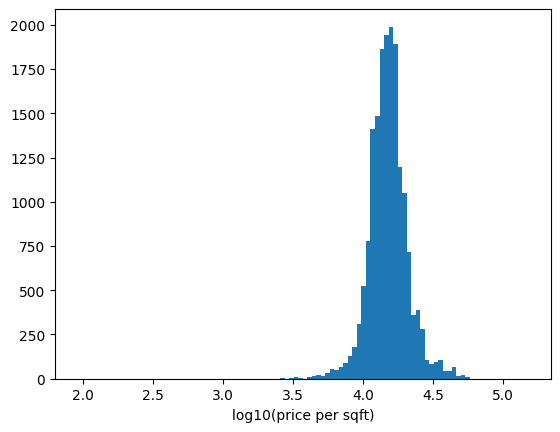

In [50]:
plt.hist(np.log10(data["Price_per_sqft"]), bins=100)
plt.xlabel("log10(price per sqft)")
plt.show()

In [51]:
lo, hi = data["Price_per_sqft"].quantile([0.001, 0.9999])
data = data[data["Price_per_sqft"].between(lo, hi)]
data.shape

(17461, 25)

In [52]:
from sklearn.model_selection import train_test_split
features = ["Area_sqft", "Bedrooms", "Bathrooms", "Kitchens", "Store Rooms", "Servant Quarters", "Built Year", "Society"]
X = data[features].copy()
y = np.log(data["Price_PKR"])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train.shape, X_test.shape

((13968, 8), (3493, 8))

In [53]:
def score(true, pred):
    err = np.abs(pred - true)
    return round(err.mean() / 1e5, 1), round(float((err / true).median()) * 100, 1)

train, test = data.loc[X_train.index], data.loc[X_test.index]
ppsf_by_society = train.groupby("Society")["Price_per_sqft"].median()
base_pred = test["Area_sqft"] * test["Society"].map(ppsf_by_society).fillna(train["Price_per_sqft"].median())
score(test["Price_PKR"], base_pred)

(np.float64(151.8), 14.2)

In [54]:
counts = X_train["Society"].value_counts()
keep = counts[counts >= 30].index
X_train["Society"] = X_train["Society"].where(X_train["Society"].isin(keep), "Other")
X_test["Society"] = X_test["Society"].where(X_test["Society"].isin(keep), "Other")

from sklearn.preprocessing import OrdinalEncoder
enc = OrdinalEncoder()
X_train["Society"] = enc.fit_transform(X_train[["Society"]])
X_test["Society"] = enc.transform(X_test[["Society"]])

In [55]:
from sklearn.ensemble import HistGradientBoostingRegressor
model = HistGradientBoostingRegressor(categorical_features=["Society"], random_state=42)
model.fit(X_train, y_train)
pred = np.exp(model.predict(X_test))
score(test["Price_PKR"], pred)

(np.float64(135.6), 12.1)

In [56]:
import joblib
joblib.dump({"model": model, "encoder": enc, "keep_societies": list(keep), "features": features}, "house_model.joblib")
print("saved")

saved
